# Weather twins — prototype

For each US city, find the famous world cities with the most similar **typical year** of weather.

- **Data:** ERA5 / ERA5-Land reanalysis (Copernicus), hourly → daily, 2016–2025, read in bulk from Open-Meteo's open data on AWS by `era5.py` into `data/daily/`.
- **Rainfall:** ERA5 rain is bias-corrected against the nearest rain gauge (NOAA GHCN-Daily / GSOD) by `rainfall.py`, or scaled to WorldClim normals where no trustworthy gauge exists; see `data/rain_stations.csv`.
- **Cities:** 56 US cities and 212 famous world cities across every climate type (`data/*.csv`).
- **Profile:** for each city, 12 monthly averages of: daily high, daily low, dew point (mugginess), rain total, rainy days, cloud cover, snowfall, wind, and day-to-day swing in highs.
- **Distance:** each feature is z-scored across all city-months, weighted (temperature highest), then compared month by month. `0` = identical; `~1` = about one standard deviation apart on average.
- **Seasons toggle:** `seasons=True` shifts Southern Hemisphere cities by 6 months, so Sydney's July is compared with your January.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import climate

pd.set_option("display.max_colwidth", 80)

us = climate.load_cities(climate.DATA_DIR / "us_cities.csv")
world = climate.load_cities(climate.DATA_DIR / "world_cities.csv")
cities = climate.all_cities()
profiles = climate.build_profiles(cities)
by_name = dict(zip(cities["name"], cities["slug"]))
have = set(profiles.index.get_level_values("slug"))
print(f"profiles for {len(have)} of {len(cities)} cities")

profiles for 268 of 268 cities


## Where each city's rainfall comes from

In [2]:
rain = pd.read_csv(climate.DATA_DIR / "rain_stations.csv")
print(rain["source"].value_counts().to_string())
rain[["name", "source", "station_name", "km", "era5_mm", "corrected_mm"]].round(0).sort_values("name").head(15)

source
ghcn         155
gsod          87
worldclim     26


,name,source,station_name,km,era5_mm,corrected_mm
142,Abidjan,gsod,ABIDJAN FELIX HOUPHOUET BOIGNY INTL,13.0,1828.0,1824.0
119,Abu Dhabi,gsod,AL BATEEN EXECUTIVE,7.0,49.0,45.0
140,Accra,gsod,KOTOKA INTL,6.0,957.0,844.0
143,Addis Ababa,gsod,BOLE INTL,8.0,1874.0,998.0
218,Adelaide,ghcn,ADELAIDE (WAITE INSTITUTE),6.0,473.0,395.0
17,Albuquerque,ghcn,ALBUQUERQUE INTL AP,6.0,168.0,182.0
134,Alexandria,gsod,ALEXANDRIA INTL,4.0,83.0,292.0
138,Algiers,worldclim,NaN,NaN,542.0,653.0
222,Alice Springs,ghcn,ALICE SPRINGS AIRPORT,11.0,227.0,291.0
210,Almaty,worldclim,NaN,NaN,824.0,515.0


## What a profile looks like

In [3]:
profiles.loc[by_name["Seattle"]].round(1)

,tmax,tmin,dewpoint,precip,rain_days,cloud,snow,wind,tmax_sd
month,,,,,,,,,
1,7.4,1.7,1.8,151.7,16.4,78.7,2.2,9.8,2.6
2,7.3,1.1,1.2,114.6,14.5,76.5,9.3,10.1,2.7
3,10.7,2.7,3.1,90.0,13.2,72.0,1.0,9.4,2.9
4,13.6,5.1,5.1,69.6,11.1,67.5,0.2,9.2,3.3
5,17.7,8.7,8.4,37.2,6.5,64.0,0.0,7.9,3.8
6,20.6,11.6,10.4,35.8,5.5,59.4,0.0,7.9,4.1
7,24.6,14.5,12.3,6.3,1.5,40.1,0.0,6.7,3.5
8,25.1,15.0,13.1,12.1,2.4,44.3,0.0,7.2,3.8
9,20.9,12.2,11.5,41.5,7.2,55.2,0.0,7.8,3.6


## Top 5 world matches for each US city (calendar months, at most 2 per country)

In [4]:
def twins(name, seasons=False, top=5, weights=None, max_per_country=2):
    return climate.find_similar(by_name[name], world, profiles, cities, weights=weights,
                                seasons=seasons, top=top, max_per_country=max_per_country)

def summary(seasons=False, top=5):
    rows = []
    for name in us["name"]:
        if by_name[name] not in have:
            continue
        t = twins(name, seasons, top)
        rows.append({"US city": name,
                     **{f"#{i + 1}": f"{r['name']} ({r['distance']:.2f})" for i, r in t.iterrows()}})
    return pd.DataFrame(rows).set_index("US city")

summary(seasons=False)

,#1,#2,#3,#4,#5
US city,,,,,
New York,Vienna (0.40),Belgrade (0.40),Seoul (0.40),Toronto (0.42),Krakow (0.42)
Los Angeles,Marrakech (0.35),Jerusalem (0.45),Amman (0.48),Casablanca (0.50),Seville (0.51)
Chicago,Toronto (0.30),Krakow (0.41),Warsaw (0.42),Vienna (0.43),Ottawa (0.44)
Houston,Shanghai (0.51),Guangzhou (0.54),Monterrey (0.57),Hanoi (0.58),Osaka (0.59)
Phoenix,Marrakech (0.55),Baghdad (0.64),Riyadh (0.66),Amman (0.68),Cairo (0.69)
Philadelphia,Belgrade (0.37),Vienna (0.39),Bucharest (0.40),Seoul (0.42),Krakow (0.45)
San Antonio,Monterrey (0.40),Valencia (0.52),Barcelona (0.57),Shanghai (0.61),Tunis (0.63)
San Diego,Casablanca (0.34),Malaga (0.43),Valencia (0.51),Tunis (0.51),Athens (0.51)
Dallas,Shanghai (0.55),Monterrey (0.56),Valencia (0.58),Dubrovnik (0.58),Split (0.61)


## Same, with Southern Hemisphere seasons aligned

In [5]:
summary(seasons=True)

,#1,#2,#3,#4,#5
US city,,,,,
New York,Vienna (0.40),Belgrade (0.40),Seoul (0.40),Toronto (0.42),Krakow (0.42)
Los Angeles,Marrakech (0.35),Jerusalem (0.45),Santiago (0.46),Amman (0.48),Casablanca (0.50)
Chicago,Toronto (0.30),Krakow (0.41),Warsaw (0.42),Vienna (0.43),Ottawa (0.44)
Houston,Shanghai (0.51),Brisbane (0.53),Buenos Aires (0.53),Rio de Janeiro (0.54),Guangzhou (0.54)
Phoenix,Marrakech (0.55),Alice Springs (0.62),Baghdad (0.64),Riyadh (0.66),Amman (0.68)
Philadelphia,Belgrade (0.37),Vienna (0.39),Bucharest (0.40),Seoul (0.42),Krakow (0.45)
San Antonio,Monterrey (0.40),Valencia (0.52),Buenos Aires (0.52),Brisbane (0.57),Barcelona (0.57)
San Diego,Casablanca (0.34),Malaga (0.43),Valparaiso (0.46),Valencia (0.51),Tunis (0.51)
Dallas,Buenos Aires (0.50),Shanghai (0.55),Montevideo (0.55),Monterrey (0.56),Valencia (0.58)


## Detail: one city, with the reason for each match

In [6]:
twins("San Francisco", top=10)[["name", "country", "distance", "why"]]

,name,country,distance,why
0,Casablanca,Morocco,0.478592,"highs +5.8°C, lows +4.9°C, more humid"
1,Malaga,Spain,0.518180,"highs +3.2°C, lows +5.6°C, more humid"
2,Lisbon,Portugal,0.530069,"highs +1.6°C, lows +3.7°C, more humid"
3,Seville,Spain,0.582437,"highs +6.7°C, lows +3.9°C, sunnier"
4,Madeira (Funchal),Portugal,0.590812,"highs +2.4°C, lows +7.0°C, more humid"
5,Marseille,France,0.595006,"highs +1.2°C, lows +2.8°C"
6,Algiers,Algeria,0.600774,"highs +4.9°C, lows +3.8°C, 1.5x the rain, more humid"
7,Athens,Greece,0.602729,"highs +4.3°C, lows +4.1°C, 1.3x drier, sunnier"
8,Palermo,Italy,0.622277,"highs +3.7°C, lows +5.9°C, more humid"
9,Jerusalem,Israel,0.624282,"highs +5.3°C, lows +2.6°C, 1.6x drier, sunnier"


In [7]:
twins("Phoenix", top=10)[["name", "country", "distance", "why"]]

,name,country,distance,why
0,Marrakech,Morocco,0.551510,"highs -3.0°C, lows -4.9°C, more humid"
1,Baghdad,Iraq,0.643082,"highs +1.8°C, lows +3.3°C, more humid"
2,Riyadh,Saudi Arabia,0.656965,"highs +2.6°C, lows +2.8°C, 1.6x drier"
3,Amman,Jordan,0.678679,"highs -5.4°C, lows -2.7°C, 1.8x the rain, more humid"
4,Cairo,Egypt,0.685259,"same temps, 2.9x drier, more humid, sunnier"
5,Athens,Greece,0.715255,"highs -7.5°C, lows -2.0°C, 2.2x the rain, more humid"
6,Jerusalem,Israel,0.730941,"highs -6.5°C, lows -3.5°C, 1.8x the rain, more humid"
7,Damascus,Syria,0.751060,"highs -6.0°C, lows -5.6°C, 2.0x the rain, more humid"
8,Seville,Spain,0.762280,"highs -5.1°C, lows -2.2°C, 3.0x the rain, more humid"
9,Valencia,Spain,0.776524,"highs -7.4°C, lows -1.9°C, 2.9x the rain, more humid, cloudier"


## Side-by-side climate charts

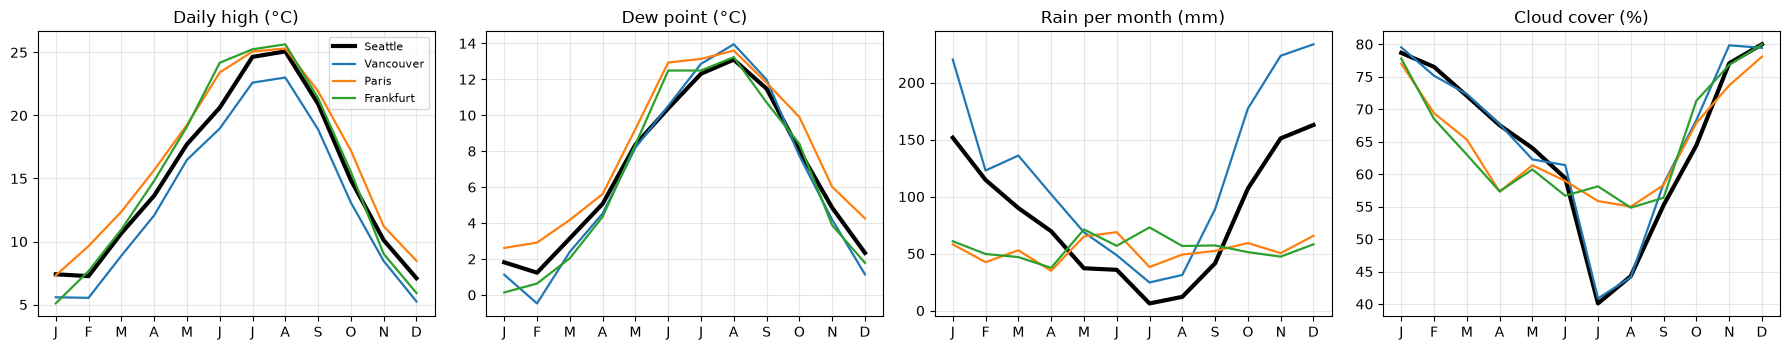

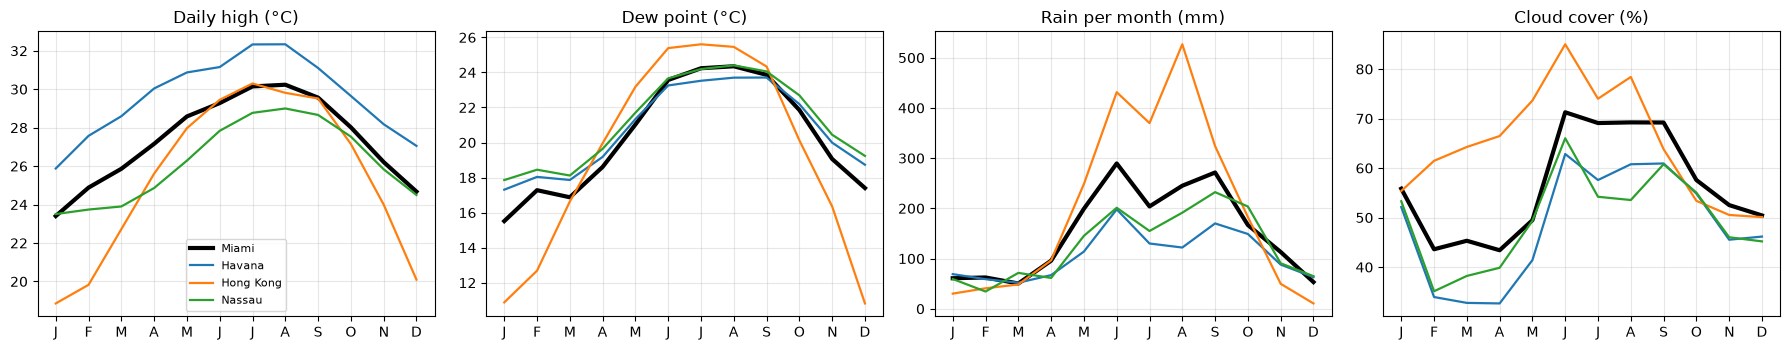

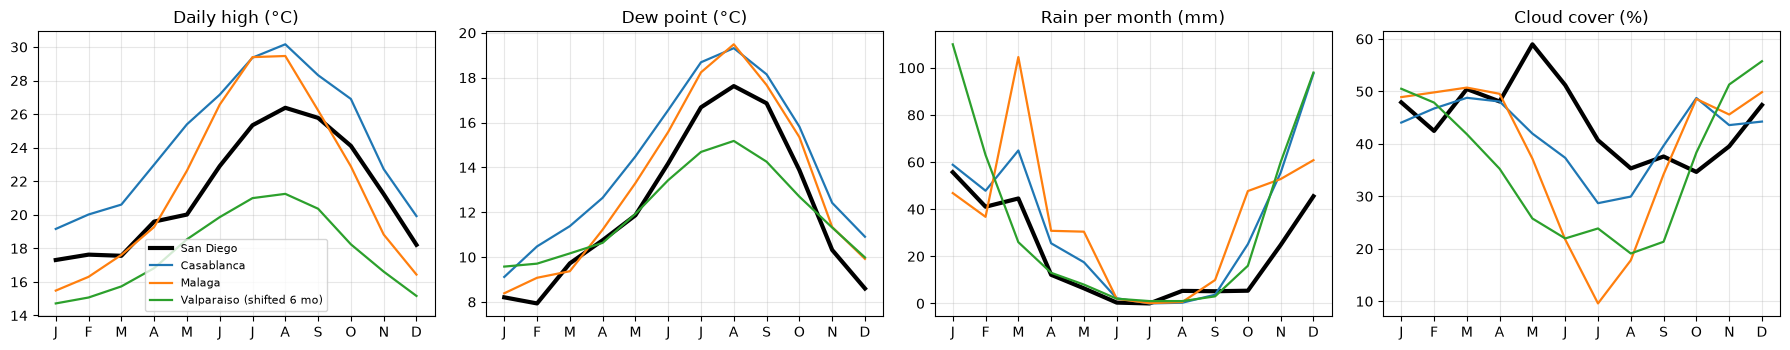

In [8]:
def compare(us_name, others, seasons=False):
    slugs = [by_name[us_name]] + [by_name[o] for o in others]
    south = set(cities.loc[cities["lat"] < 0, "slug"])
    fig, axes = plt.subplots(1, 4, figsize=(18, 3.6))
    panels = [("tmax", "Daily high (°C)"), ("dewpoint", "Dew point (°C)"),
              ("precip", "Rain per month (mm)"), ("cloud", "Cloud cover (%)")]
    months = list("JFMAMJJASOND")
    for ax, (col, title) in zip(axes, panels):
        for i, s in enumerate(slugs):
            y = profiles.loc[s, col].to_numpy()
            label = cities.set_index("slug").loc[s, "name"]
            if seasons and s in south:
                y = list(y[6:]) + list(y[:6])
                label += " (shifted 6 mo)"
            ax.plot(range(12), y, lw=3 if i == 0 else 1.6,
                    color="black" if i == 0 else None, label=label)
        ax.set_title(title)
        ax.set_xticks(range(12), months)
        ax.grid(alpha=0.3)
    axes[0].legend(fontsize=8)
    plt.tight_layout()
    plt.show()

def compare_top(us_name, n=3, seasons=False):
    compare(us_name, list(twins(us_name, seasons, n)["name"]), seasons)

compare_top("Seattle")
compare_top("Miami")
compare_top("San Diego", seasons=True)

## Play with the weights

Weights live in `climate.FEATURES`. Override any of them, e.g. ignore rain and care a lot about humidity:

In [9]:
twins("Houston", top=8, weights={"precip": 0, "rain_days": 0, "dewpoint": 2.0})[["name", "country", "distance", "why"]]

,name,country,distance,why
0,Guangzhou,China,0.347627,"highs +0.7°C, lows +2.4°C, 1.7x the rain, cloudier"
1,Monterrey,Mexico,0.438191,"highs +1.2°C, lows +0.1°C, 2.0x drier, drier air, sunnier"
2,Hong Kong,China,0.458326,"highs -0.6°C, lows +3.9°C, 1.8x the rain, more humid"
3,Taipei,Taiwan,0.461165,"highs -0.8°C, lows +3.3°C, 2.2x the rain, more humid, cloudier"
4,Hanoi,Vietnam,0.511007,"highs +1.6°C, lows +3.7°C, 1.4x the rain, more humid, cloudier"
5,Casablanca,Morocco,0.512127,"highs -1.6°C, lows -2.2°C, 3.3x drier, drier air, sunnier"
6,Valencia,Spain,0.561158,"highs -3.0°C, lows -2.9°C, 3.0x drier, drier air, sunnier"
7,Palma de Mallorca,Spain,0.566704,"highs -4.0°C, lows -1.1°C, 2.9x drier, drier air, sunnier"
